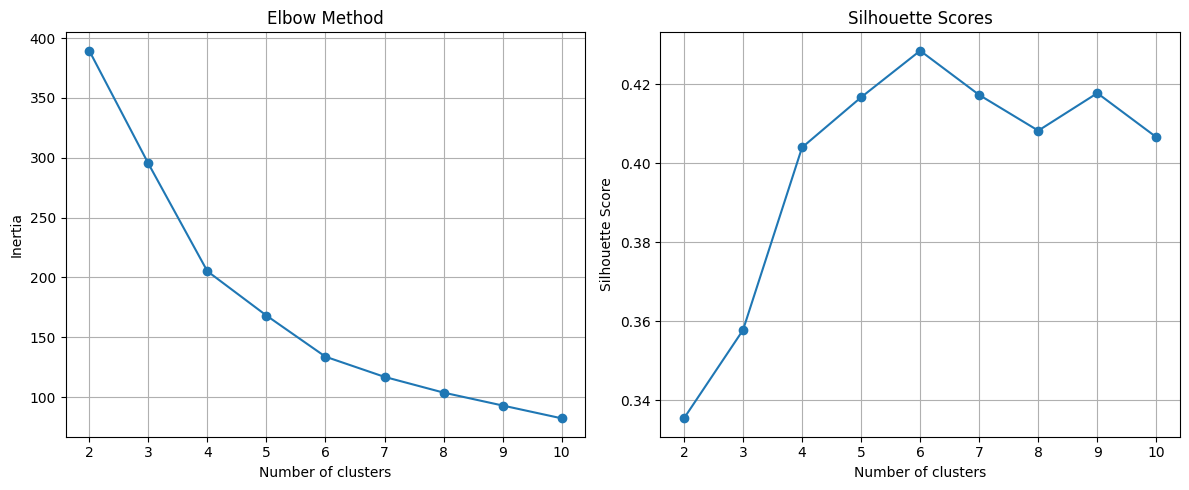


Cluster Profile (Mean Values):
               Age  Annual_Income_(k$)  Spending_Score
Cluster                                               
0        46.250000           26.750000       18.350000
1        25.185185           41.092593       62.240741
2        32.875000           86.100000       81.525000
3        39.871795           86.102564       19.358974
4        55.638298           54.382979       48.851064


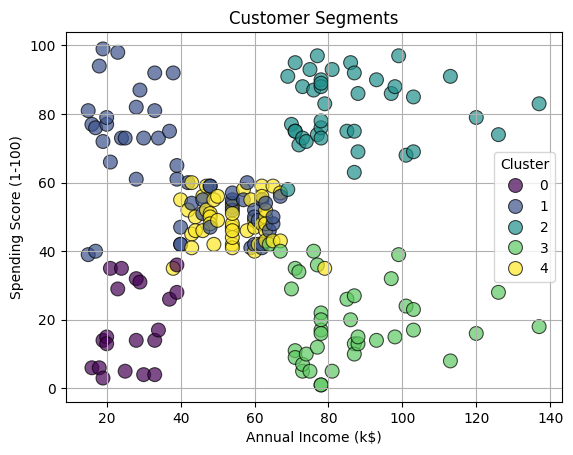

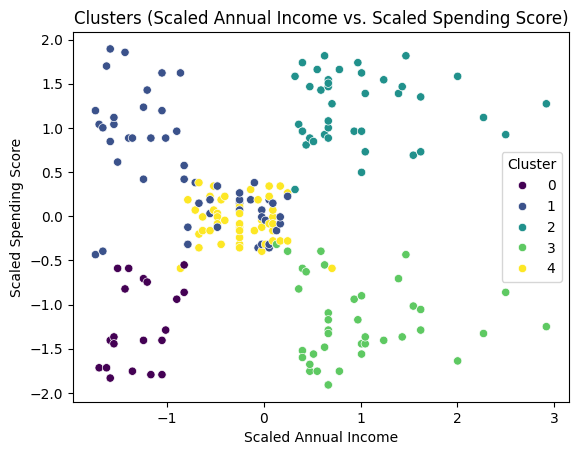

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data_exp5.csv")

X = df[['Age', 'Annual_Income_(k$)', 'Spending_Score']]
X = StandardScaler().fit_transform(X)

inertia, sil = [], []
K = range(2, 11)

for k in K:
    m = KMeans(n_clusters=k, random_state=42, n_init=10)
    y = m.fit_predict(X)
    inertia.append(m.inertia_)
    sil.append(silhouette_score(X, y))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(K, inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(K, sil, marker='o')
plt.title("Silhouette Scores")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette Score")
plt.grid()

plt.tight_layout()
plt.savefig("elbow_silhouette.png")
plt.show()

df['Cluster'] = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X)
print("\nCluster Profile (Mean Values):")
print(df.groupby('Cluster')[['Age', 'Annual_Income_(k$)',
      'Spending_Score']].mean())

sns.scatterplot(data=df, x='Annual_Income_(k$)',
                y='Spending_Score', hue='Cluster',
                palette='viridis', s=100, alpha=0.7, edgecolor='k')
plt.title("Customer Segments")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.grid()
plt.savefig("cluster_scatterplot.png")
plt.show()

sns.scatterplot(x=X[:, 1], y=X[:, 2], hue=df['Cluster'],
                palette='viridis')
plt.title("Clusters (Scaled Annual Income vs. Scaled Spending Score)")
plt.xlabel("Scaled Annual Income")
plt.ylabel("Scaled Spending Score")
plt.savefig("clusters_scaled.png")
plt.show()